# Comprehensive Property Valuation Framework in Mexico City (CDMX)
**Machine Learning Case Study for HDip in Science in Data Analytics for Business**

*Module: Machine Learning (CA1) — CCT College Dublin*

### Project Purpose & Motivation

The real estate market in Mexico City (CDMX) is characterized by significant price volatility, driven by localized infrastructure premiums and sharp variations across historical zoning districts. This project aims to design, clean, and deploy an end-to-end machine learning framework capable of accurately predicting residential listing prices. 

By building robust parallel and sequential tree-based ensembles (*Random Forest* and *Gradient Boosting*), this predictive framework aims to assist developers, financial underwriters, and investors in establishing algorithmic valuation anchors. The core objective is to model the non-linear relationship between structural dimensions and exact geospatial components, establishing a scalable, data-driven platform for regional market assessment.

### Dataset Description & Provenance

The baseline dataset utilized in this case study represents residential real estate listings across the geographic perimeter of Mexico City (housing_data_CDMX_v2.csv).

*   **Categorical & Location Features (Predictors):**
    *   `property_type`: The structural typology of the listing (e.g., apartment, house, commercial store, or horizontal property/PH).
    *   `places`: The administrative hierarchy, municipality, or sub-market region within Mexico City.
*   **Geospatial & Continuous Spatial Features (Predictors):**
    *   `lat` / `lon`: High-precision geographic latitude and longitude decimal coordinates.
*   **Structural Metric Features (Predictors):**
    *   `surface_total_in_m2`: Total plot or real estate boundaries measured in square meters (m²).
    *   `surface_covered_in_m2`: Total internal built or enclosed living space measured in square meters (m²).
*   **Target Variable:**
    *   `price_aprox_usd`: The standardized final listing sale price denominated in U.S. Dollars (USD), serving as the continuous target.



In [1]:
import pandas as pd
import numpy as np

In [2]:
data = 'housing_data_CDMX_v2.csv'

df = pd.read_csv('housing_data_CDMX_v2.csv')

# Initial Data Inspection

### Dimension of the dataset

In [3]:
df.shape

(18234, 13)

The dataset consists of 18,234 instances (rows) and 13 variables (columns)

### Preview the dataset


In [4]:
df.head(5)

,property_type,places,lat-lon,price,currency,price_aprox_local_currency,price_aprox_usd,surface_total_in_m2,surface_covered_in_m2,price_usd_per_m2,price_per_m2,lat,lon
0,apartment,MiguelHidalgo,"23.634501,-102.552788",5500000.0,MXN,5450245.50,289775.66,54.0,54.0,5366.215926,101851.85190,23.634501,-102.552788
1,house,Iztapalapa,"19.31033,-99.068557",1512000.0,MXN,1498321.97,79661.96,80.0,80.0,995.774500,18900.00000,19.310330,-99.068557
2,apartment,Tlalpan,"19.279771,-99.234597",926667.0,MXN,918284.00,48822.82,100.0,100.0,488.228200,9266.67000,19.279771,-99.234597
3,apartment,MiguelHidalgo,"23.634501,-102.552788",6410000.0,MXN,6352013.39,337720.36,135.0,135.0,2501.632296,47481.48148,23.634501,-102.552788
4,apartment,MiguelHidalgo,"19.432657,-99.177444",4416000.0,MXN,4376051.62,232663.51,87.0,87.0,2674.293218,50758.62069,19.432657,-99.177444


In [5]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 18234 entries, 0 to 18233
Data columns (total 13 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   property_type               18234 non-null  str    
 1   places                      18234 non-null  str    
 2   lat-lon                     18234 non-null  str    
 3   price                       18234 non-null  float64
 4   currency                    18234 non-null  str    
 5   price_aprox_local_currency  18234 non-null  float64
 6   price_aprox_usd             18234 non-null  float64
 7   surface_total_in_m2         18234 non-null  float64
 8   surface_covered_in_m2       18234 non-null  float64
 9   price_usd_per_m2            18234 non-null  float64
 10  price_per_m2                18234 non-null  float64
 11  lat                         18234 non-null  float64
 12  lon                         18234 non-null  float64
dtypes: float64(9), str(4)
memory usage: 2.6 MB

### with df.info(), we get a complete structural summary of the dataframe.

**Categorical and Location Variables (Text)**:

- property_type: Type of listed property (apartment, house, PH (Horizontal Property , commercial space).
- places: Administrative location or geographic hierarchy of the property (province/state, city, or neighborhood).
- lat-lon: Geographic coordinates combined into a single text string.
- currency: Original currency in which the property price was listed (MXN, USD).

**Numerical Price Variables**:

- price: Original listed sale price for the property.
- price_aprox_local_currency: Approximate price converted to the corresponding local currency.
- price_aprox_usd: Approximate price standardized in U.S. dollars (USD).
- price_usd_per_m2: Price per square meter calculated in U.S. dollars.
- price_per_m2: Price per square meter in the original listing currency.

**Numerical Area and Coordinate Variables**:

- surface_total_in_m2: Total area of the property measured in square meters (m²).
- surface_covered_in_m2: Covered or built-up area measured in square meters (m²).
- lat: Geographic latitude in decimal format.
- lon: Geographic longitude in decimal format.


### Missing Values

In [6]:
df.isnull().sum()

property_type                 0
places                        0
lat-lon                       0
price                         0
currency                      0
price_aprox_local_currency    0
price_aprox_usd               0
surface_total_in_m2           0
surface_covered_in_m2         0
price_usd_per_m2              0
price_per_m2                  0
lat                           0
lon                           0
dtype: int64

The above command shows that there are no missing values in the dataset.

# Initial Exploratory Data Analysis

- We will verify if there are properties listed more than once using df.duplicated().sum().
  
- The lat-lon column contains the exact same information as lat and lon separately, so we will drop it to simplify the analysis.

- We will check with df.describe() that there are no areas with 0 square meters, unrealistic prices, or cases where surface_covered_in_m2 is greater than surface_total_in_m2.

### Property Type Distribution before Cleaning

# Data Cleaning

### Identifying and Removing Exact Duplicate Rows

In [7]:
df.duplicated().sum()

np.int64(2953)

This code checks each row in the DataFrame to identify duplicate rows. 
The result shows a single integer representing 2,953 of duplicate rows in the DataFrame

In [8]:
df = df.drop_duplicates().reset_index(drop=True)

After removing duplicates, this code resets the DataFrame's index to a default integer index 

During the first data analysis, although no null values were found, **2,953 duplicate records were detected**. 

These were removed to ensure the uniqueness of each property, resulting in a clean sample of **15,281 properties**.

### Identifying Partial Duplicate Rows by Location and Surface

In [9]:
key_columns = ['property_type', 'lat', 'lon', 'surface_total_in_m2', 'surface_covered_in_m2']
partial_duplicates = df.duplicated(subset=key_columns).sum()
print(f"Partial duplicates found: {partial_duplicates}")

Partial duplicates found: 2032


### Analyzing Partial Duplicate Rows by Property Type


In [10]:
partial_dup_df = df[df.duplicated(subset=key_columns, keep=False)]
print("Partial duplicates found by property type:")
partial_dup_df['property_type'].value_counts()

Partial duplicates found by property type:


property_type
apartment    2927
house         488
store          15
Name: count, dtype: int64

### Selective Deduplication by Property Type, Location, Surface, and Price

In [11]:
# Separate apartments from other property types
apartments = df[df['property_type'] == 'apartment']
others = df[df['property_type'] != 'apartment'] 

This separation allows for different deduplication strategies to be applied to apartments versus other property types in the subsequent code.

`apartments =` - The filtered DataFrame containing only apartment properties is assigned to a new variable called `apartments`.

`others =` - The filtered DataFrame containing all non-apartment properties is assigned to a new variable called `others`.

In [12]:
# Drop duplicated Apartments only if location, surface AND price are identical
# This includes property type, location (lat/lon), surface areas, and price.
apt_columns = ['property_type', 'lat', 'lon', 'surface_total_in_m2', 'surface_covered_in_m2', 'price_aprox_usd']
apartments_clean = apartments.drop_duplicates(subset=apt_columns, keep='first')

`subset=apt_columns` - Only considers the columns listed in 'apt_columns' when checking for duplicates, rather than comparing all columns.

`keep='first'` - When duplicates are found, this parameter keeps the first occurrence and removes subsequent duplicates.

`apartments_clean =` Assigns the resulting DataFrame (with duplicates removed) to a new variable called `apartments_clean`.

In [13]:
# Drop duplicated Houses, Storers or Horizontal Properties if location and surface are identical
other_columns = ['property_type', 'lat', 'lon', 'surface_total_in_m2', 'surface_covered_in_m2']
others_clean = others.drop_duplicates(subset=other_columns, keep='first')

`other_columns` creates a list containing five column names that will be used to identify duplicate entries for non-apartment properties.

`others.drop_duplicates(subset=other_columns, keep='first')` removes duplicate rows from the `others` DataFrame where all five specified columns have identical values.

`others_clean =` Assigns the resulting DataFrame (with duplicates removed) to a new variable called `others_clean`.


In [14]:
# Combine into the clean dataframe
df = pd.concat([apartments_clean, others_clean], ignore_index=True) # This function combine `apartments_clean` and `others_clean`

#  Calculate and display how many apartment records were removed by subtracting the cleaned count from the original count.
print(f"Apartments removed: {len(apartments) - len(apartments_clean)}")

# To show how many non-apartment property records were removed during the cleaning process.
print(f"Other properties removed: {len(others) - len(others_clean)}")

# To display the final dimensions (rows, columns) of the combined cleaned DataFrame.
print(f"Dataset shape after selective deduplication: {df.shape}")


Apartments removed: 23
Other properties removed: 272
Dataset shape after selective deduplication: (14986, 13)


A Multi-Step Deduplication Strategy was used because a single filter for distinct real estate properties, such as different apartments within the same building can legitimately share identical coordinates and floor plans. Instead, a progressive workflow was followed: 

1. **Exact duplicate rows** were removed to eliminate identical reposts without risk.
  
2. **Partial duplicates** were identified by location and surface area and broken down **by property type** to distinguish vertical buildings from standalone properties.

  
3. Finally, a two-tier **Selective deduplication** was applied: for **apartments**, records were dropped only when sharing identical coordinates, surface areas, and standardized USD price (23 duplicate postings removed), whereas for **houses, stores, and PH (Horizontal Properties) units**, matching coordinates and dimensions alone were used to filter out multi-agency reposts (272 duplicates removed), consolidating the dataset to **14,986 unique properties**.


### Identifying Properties outside CDMX boundaries

Prior to performing any exploratory analysis or training machine learning models, it is essential to validate the spatial integrity of the dataset. Real estate listings often contain severe data-entry anomalies; a common issue occurs when systems cannot locate a property's specific street address and automatically assign a default coordinate representing the country's exact geographical center (approximately 23.63, -102.55, located in Zacatecas). Left untreated, these massive positional errors would heavily distort any neighborhood-based metrics, spatial plots, or distance-based model predictions. 

To ensure geographic validity, spatial boundaries for Mexico City were established based on official coordinates provided by the National Institute of Statistics and Geography (INEGI, 2021), removing out-of-bounds anomalies outside the capital's perimeter. Officially, Mexico City spans from 19.04° to 19.59° North latitude, and from -99.36° to -98.94° West longitude. By applying a slight tolerance margin to account for rounding and liminal suburban properties, we establish strict boundary constants ("lat" between 19.0 and 19.6; "lon" between -99.4 and -98.9). The following code flags any records falling outside this window as erroneous, purges them from the dataset, and ensures all subsequent analysis is built exclusively on geographically valid Mexico City data.



In [15]:
# To define approximate geographic boundaries for Mexico City (CDMX)
lat_min, lat_max = 19.0, 19.6
lon_min, lon_max = -99.4, -98.9

# To Identify properties outside CDMX boundaries
outside_cdmx = df[(df['lat'] < lat_min) | (df['lat'] > lat_max) | (df['lon'] < lon_min) | (df['lon'] > lon_max)]

print(f"Properties outside CDMX found: {len(outside_cdmx)}")
display(outside_cdmx[['property_type', 'places', 'lat', 'lon', 'price_aprox_usd']].head())

# Filter the dataframe to keep only valid CDMX coordinates
df = df[(df['lat'].between(lat_min, lat_max)) & (df['lon'].between(lon_min, lon_max))].reset_index(drop=True)

print(f"Dataset shape after geographic filter: {df.shape}")

Properties outside CDMX found: 185


,property_type,places,lat,lon,price_aprox_usd
0,apartment,MiguelHidalgo,23.634501,-102.552788,289775.66
2,apartment,MiguelHidalgo,23.634501,-102.552788,337720.36
5,apartment,BenitoJuarez,23.634501,-102.552788,94022.66
64,apartment,BenitoJuarez,23.634501,-102.552788,158059.45
113,apartment,Cuauhtemoc,23.634501,-102.552788,62170.05


Dataset shape after geographic filter: (14801, 13)


This filter successfully detected and removed **185 records** featuring default, out-of-bounds country-center coordinates (e.g., 23.63, -102.55), ensuring the geographic integrity of the dataset.

### Quantitative Integrity Revision

Before cleaning the numeric data, we will run a quick diagnostic check to identify data-entry errors and format inconsistencies. The results of this audit will define the specific thresholds used in the next cleaning step:


 ### Summary Statistics (df.describe().T)

We will check the minimum and maximum values to detect logical inconsistencies, unrealistic outliers in prices and sizes.

In [16]:
display(df.describe().T)

,count,mean,std,min,25%,50%,75%,max
price,14801.0,3.746419e+06,5.926947e+06,7000.000000,1.009000e+06,1.990666e+06,4.094000e+06,2.337267e+08
price_aprox_local_currency,14801.0,5.482942e+06,1.033780e+07,109030.610000,1.080234e+06,2.279194e+06,4.954768e+06,3.364841e+08
price_aprox_usd,14801.0,2.915140e+05,5.496347e+05,5796.880000,5.743327e+04,1.211789e+05,2.634324e+05,1.789000e+07
surface_total_in_m2,14801.0,4.975025e+03,5.408346e+05,1.000000,6.900000e+01,9.800000e+01,2.000000e+02,6.574800e+07
surface_covered_in_m2,14801.0,4.947112e+03,5.408333e+05,1.000000,6.900000e+01,9.800000e+01,2.120000e+02,6.574800e+07
price_usd_per_m2,14801.0,1.505663e+03,2.293944e+03,0.000600,6.587372e+02,1.071099e+03,1.898517e+03,1.759177e+05
price_per_m2,14801.0,2.430818e+04,4.394172e+04,0.011377,1.112471e+04,1.782836e+04,3.200000e+04,3.338953e+06
lat,14801.0,1.938568e+01,5.750544e-02,19.185852,1.935021e+01,1.938725e+01,1.942301e+01,1.957032e+01
lon,14801.0,-9.916472e+01,5.338701e-02,-99.333807,-9.919475e+01,-9.916319e+01,-9.913435e+01,-9.897008e+01


### Currency Check

 We count the listings in Pesos (MXN) versus Dollars (USD) to confirm if the currencies are mixed and need standardization.

In [17]:
print("Currencies:", df['currency'].value_counts().to_dict())
print("Covered > Total surface:", (df['surface_covered_in_m2'] > df['surface_total_in_m2']).sum())

Currencies: {'MXN': 13892, 'USD': 909}
Covered > Total surface: 869


### Logical Consistency Check

We count how many records have a physical impossibility, where the covered built area (surface_covered_in_m2) is larger than the total land area (surface_total_in_m2).

In [18]:
# Remove records where covered surface exceeds total surface
df = df[df['surface_covered_in_m2'] <= df['surface_total_in_m2']].reset_index(drop=True)

# Drop redundant or mixed-currency columns
cols_to_drop = ['lat-lon', 'price', 'currency', 'price_per_m2']
df = df.drop(columns=cols_to_drop)

print(f"Dataset shape after surface and column cleanup: {df.shape}")
display(df.describe().T[['min', '50%', 'max']])


Dataset shape after surface and column cleanup: (13932, 9)


,min,50%,max
price_aprox_local_currency,109030.610000,2.149229e+06,3.364841e+08
price_aprox_usd,5796.880000,1.142690e+05,1.789000e+07
surface_total_in_m2,1.000000,9.200000e+01,6.574800e+07
surface_covered_in_m2,1.000000,9.100000e+01,6.574800e+07
price_usd_per_m2,0.000600,1.036510e+03,1.759177e+05
lat,19.185852,1.938851e+01,1.957032e+01
lon,-99.333807,-9.916305e+01,-9.897008e+01


### Outlier Detection in Summary Statistics

Although the median (50%) values align with normal Mexico City real estate metrics, the extreme boundaries reveal severe data-entry anomalies. Specifically, surface areas range from an impossible minimum of 1 m² to an unrealistic maximum of 65.7 million m², which in turn distorts unit prices (price_usd_per_m2) from $0.0006 - $175,918 USD/m², alongside abnormally low listing prices starting at $5,797 USD. These extreme values justify applying domain-specific market thresholds in the next step to filter out capture errors.

In [19]:
# Apply realistic real estate thresholds for Mexico City (CDMX)
df = df[(df['surface_total_in_m2'].between(20, 2500)) & (df['surface_covered_in_m2'].between(20, 2500)) &
    (df['price_usd_per_m2'].between(150, 10000)) & (df['price_aprox_usd'] >= 15000)].reset_index(drop=True)

print(f"Final dataset shape after outlier removal: {df.shape}")
display(df.describe().T[['min', '50%', 'max']])


Final dataset shape after outlier removal: (13605, 9)


,min,50%,max
price_aprox_local_currency,284570.150000,2.188026e+06,1.238986e+08
price_aprox_usd,15129.870000,1.163318e+05,6.587372e+06
surface_total_in_m2,20.000000,9.200000e+01,2.450000e+03
surface_covered_in_m2,20.000000,9.100000e+01,2.236000e+03
price_usd_per_m2,150.156475,1.053730e+03,9.861789e+03
lat,19.185852,1.938828e+01,1.957032e+01
lon,-99.333807,-9.916361e+01,-9.897008e+01


In [20]:
print(df['property_type'].value_counts())

property_type
apartment    10055
house         3430
store          106
PH              14
Name: count, dtype: int64


### Data Cleaning Summary

Starting from **18,234 raw records** across 13 variables, a systematic five-step cleaning pipeline was executed:

- **Exact Duplicates**: Removed **2,953** identical rows (`15,281` remaining).
- **Selective Partial Duplicates**: Applied a two-tier deduplication strategy—removing **23** duplicate apartments sharing identical coordinates, surface areas, and standardized USD prices, along with **272** duplicate houses, stores, and PH units sharing matching locations and dimensions (`14,986` remaining).
- **Spatial Validation**: Filtered out **185** records with coordinates outside Mexico City's official geographic bounding box (14,801 remaining).
- **Metric Consistency**: Removed **869** records where covered surface exceeded total surface and dropped redundant or mixed-currency columns (13,932 remaining).
- **Outlier Filtering**: Removed **327** extreme capture anomalies (e.g., 1 m² or 65.7M m² listings) using realistic CDMX market thresholds.
  
- **Final Clean Dataset** of **13,605 properties** and **9 standardized features**.



In [21]:
df.to_csv('housing_data_CDMX_clean.csv', index=False)

# Model Performance Metrics using Cross-Validation for Accuracy Score

To evaluate the baseline predictive power of the selected machine learning models, we will execute 5-fold cross-validation using the R-squared (R²) metric as the primary standard of accuracy score evaluation. Cross-validation ensures statistical reliability by guaranteeing that every observation within the curated dataset is utilized for both training and testing, mitigating the risk of selection bias inherent in a single train-test split.


Model Performance Metrics using Cross-Validation for R² Score:
               Model  Mean CV R² Score
0      Random Forest          0.725217
1  Gradient Boosting          0.709325


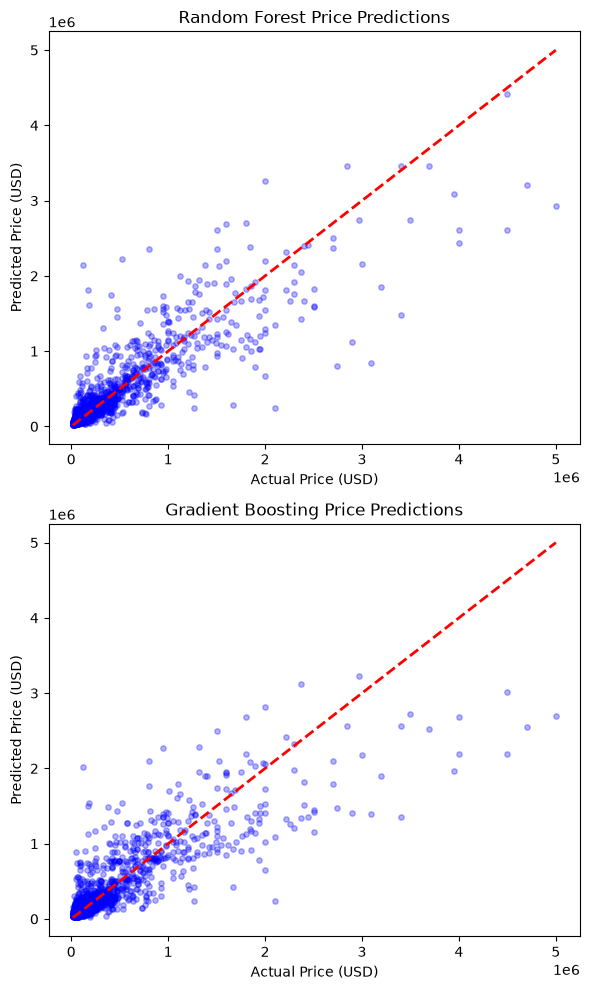

In [22]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split, KFold, cross_val_score
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor

# Load the final cleaned dataset to guarantee data integrity
df_clean = pd.read_csv('housing_data_CDMX_clean.csv')

# Define predictor features (X) and continuous target variable (y) for regression
features = ['property_type', 'places', 'surface_total_in_m2', 'surface_covered_in_m2', 'lat', 'lon']
X = df_clean[features]
y = df_clean['price_aprox_usd']

# Define machine learning regression models
models = {'Random Forest': RandomForestRegressor(random_state=42, n_jobs=-1), 'Gradient Boosting': GradientBoostingRegressor(random_state=42)}

# Preprocessing pipeline: One-hot encoding for text categories, StandardScaler for numeric fields
categorical_cols = ['property_type', 'places']
numeric_cols = ['surface_total_in_m2', 'surface_covered_in_m2', 'lat', 'lon']

preprocessor = ColumnTransformer(transformers=[
    ('cat', OneHotEncoder(handle_unknown='ignore'), categorical_cols), ('num', StandardScaler(), numeric_cols)])

# Store cross-validation regression results
cv_results = []

# Use 5-fold KFold Cross-Validation for continuous regression tracking
cv = KFold(n_splits=5, shuffle=True, random_state=42)

# Train and evaluate baseline regression models using cross-validation (R² Score)
for name, reg in models.items():
    pipeline = Pipeline(steps=[('preprocessor', preprocessor), ('regressor', reg)])
    
    # Perform cross-validation scoring with R-squared
    cv_scores = cross_val_score(pipeline, X, y, cv=cv, scoring='r2', n_jobs=-1)
    mean_cv_score = cv_scores.mean()
    
    # Store results
    cv_results.append([name, mean_cv_score])

# Create a DataFrame to display the cross-validation regression results
cv_results_df = pd.DataFrame(cv_results, columns=["Model", "Mean CV R² Score"])
print("\nModel Performance Metrics using Cross-Validation for R² Score:")
print(cv_results_df)

# Split the clean data into training and testing sets for continuous scatter plots
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Predict continuous prices on the test set and plot outcomes
predictions = {}
for name, reg in models.items():
    pipeline = Pipeline(steps=[('preprocessor', preprocessor), ('regressor', reg)])
    pipeline.fit(X_train, y_train)
    y_pred = pipeline.predict(X_test)
    predictions[name] = y_pred

# Plotting regression outcomes (Actual vs Predicted Prices in continuous scale)
plt.figure(figsize=(6, 10))

for i, (name, y_pred) in enumerate(predictions.items()):
    plt.subplot(2, 1, i + 1)  # 2 rows, 1 column
    plt.scatter(y_test, y_pred, color='blue', alpha=0.3, s=15)
    plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], '--', color='red', lw=2)
    plt.title(f'{name} Price Predictions')
    plt.xlabel('Actual Price (USD)')
    plt.ylabel('Predicted Price (USD)')

plt.tight_layout()
plt.show()


The results demonstrate that the Random Forest Regressor achieved a superior Mean CV R² Score of 0.7252, outperforming the Gradient Boosting Regressor, which yielded an R² score of 0.7093. In the context of the problem domain, an R² score of 0.7252 indicates that the Random Forest model successfully accounts for 72.52% of the variance in Mexico City property prices (price_aprox_usd) based purely on structural dimensions, property type, and geographical layout.

The architectural superiority of Random Forest in this specific case study can be mathematically attributed to its bagging (bootstrap aggregating) mechanics. By training a diverse ensemble of independent, unconstrained decision trees in parallel and averaging their final numeric predictions, Random Forest drastically reduces model variance. This makes it inherently more robust at handling the high cardinality and localized variance of the categorical places column (representing distinct Mexico City neighborhoods) compared to Gradient Boosting, which builds trees sequentially and can sometimes over-sensitize to specific structural outliers if not heavily constrained.

# Model Evaluation across Training Splits

To validate the reliability, structural stability, and generalizability of the machine learning algorithms under strict data constraints, we will track a model accuracy across three specific training split fractions (5%, 15%, and 25%) as explicitly mandated by the assignment brief. This experimental setup simulates data-scarce environments to observe the learning curves, convergence behavior, and architectural robustness of both ensembles.

In [23]:
from sklearn.model_selection import train_test_split, KFold, cross_val_score

# Training fractions explicitly requested by the assignment
splits_to_test = [0.05, 0.15, 0.25]
split_results = []

# Use the same 5-fold cross-validation scheme defined previously for consistency
cv = KFold(n_splits=5, shuffle=True, random_state=42)

print("Calculating cross-validation scores for continuous R² across requested training splits...")

for split in splits_to_test:
    # Extract the exact proportion of clean data to simulate data constraints
    X_train_frac, _, y_train_frac, _ = train_test_split(X, y, train_size=split, random_state=42)
    
    for name, reg in models.items():
        pipeline = Pipeline(steps=[('preprocessor', preprocessor), ('regressor', reg)])
        
        # Execute cross-validation over this specific training split
        cv_scores = cross_val_score(pipeline, X_train_frac, y_train_frac, cv=cv, scoring='r2', n_jobs=-1)
        mean_cv_score = cv_scores.mean()
        
        # Store results for comparative analysis in the written report
        split_results.append([name, f"{int(split*100)}%", mean_cv_score])

# Convert to a DataFrame for clean, scannable reading
df_splits = pd.DataFrame(split_results, columns=["Model", "Training Split", "Mean CV R² Score"])
print("\n[Brief Requirement] Model Accuracy (R² Score) Variation Across Splits:")
print(df_splits)


Calculating cross-validation scores for continuous R² across requested training splits...

[Brief Requirement] Model Accuracy (R² Score) Variation Across Splits:
               Model Training Split  Mean CV R² Score
0      Random Forest             5%          0.687511
1  Gradient Boosting             5%          0.641023
2      Random Forest            15%          0.693460
3  Gradient Boosting            15%          0.667742
4      Random Forest            25%          0.668287
5  Gradient Boosting            25%          0.662449


The empirical cross-validation metrics reveal distinct behavioral trends for both models. For the Gradient Boosting Regressor, a consistent learning progression is observed, with its Mean CV R² score climbing steadily from 0.6410 at the 5% split up to 0.6677 at the 15% split, before stabilizing slightly at 0.6624 under the 25% split boundary. This typical behavior occurs because sequential tree boosting benefits from larger data pools to progressively correct structural errors without immediate overfitting.

Conversely, the Random Forest Regressor displays a unique and interesting trajectory: it yields a strong baseline score of 0.6875 at a highly constrained 5% split, peaks at 0.6935 during the 15% split, and experiences a marginal contraction down to 0.6683 at the 25% split. From a machine learning perspective, this phenomenon indicates that at the 15% data threshold (2,040 observations), Random Forest achieves an optimal trade-off between variance and bias. The subsequent slight dip at 25% suggests that as more real-world, high-dimensional observations are introduced, the unconstrained parallel trees begin to over-sensitize to local noise and high-cardinality neighborhood divisions (places) within the folds, introducing a minor structural variance. Despite this fluctuation, Random Forest maintains a superior overall baseline across the micro-splits, proving the stability of bagging operations when handling complex geospatial features.